In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Ingresos frente al salario mínimo

¿Cuántos ocupados ganan el salario mínimo, cuántos menos y cuántos más? La variable armonizada
`ratio_smlv` es el ingreso laboral mensual dividido por el salario mínimo del año (`dd.SMLV`).

In [2]:
import numpy as np

import dane_data as dd

df = dd.geih.load(2025, variables=["fex", "ocupado", "formal", "ingreso_laboral", "ratio_smlv"])
ocupados = df[(df.ocupado == 1) & df.ingreso_laboral.notna()]
dd.SMLV[2025], len(ocupados)

(1423500, 349830)

## La distribución

El histograma usa el factor de expansión como peso (dividido por 12, porque son doce meses):

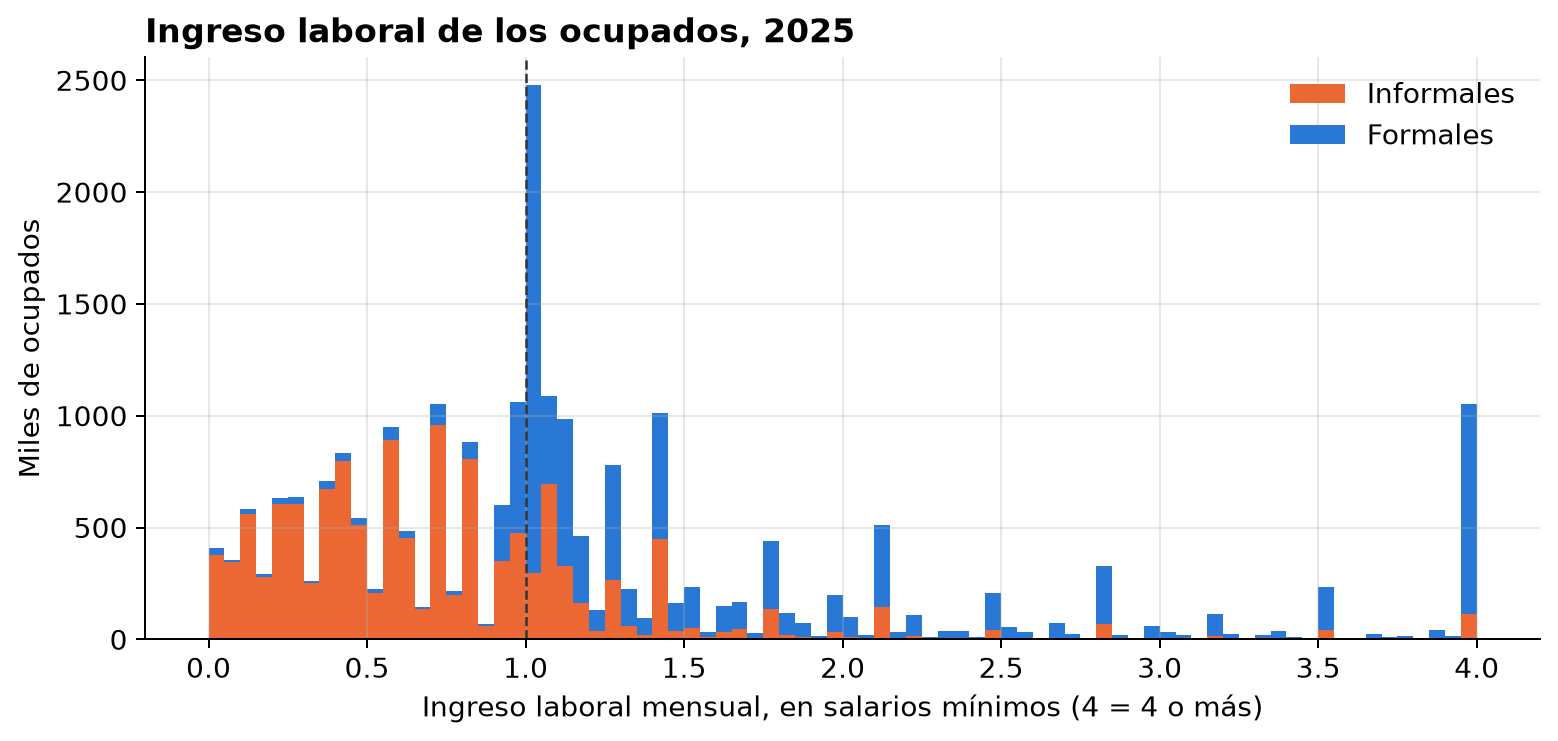

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.arange(0, 4.01, 0.05)
grupos = [ocupados[ocupados.formal == 0], ocupados[ocupados.formal == 1]]
ax.hist([d["ratio_smlv"].clip(upper=4) for d in grupos], bins=bins, stacked=True,
        weights=[d["fex"] / 12 / 1e3 for d in grupos], color=["#eb6834", "#2a78d6"],
        label=["Informales", "Formales"])
ax.axvline(1, color="0.2", lw=1, ls="--")
ax.set_xlabel("Ingreso laboral mensual, en salarios mínimos (4 = 4 o más)")
ax.set_ylabel("Miles de ocupados")
ax.set_title("Ingreso laboral de los ocupados, 2025")
ax.legend();

La distribución tiene un pico enorme justo en un salario mínimo, sobre todo entre los formales: el mínimo
es un piso efectivo para el empleo formal. Entre los informales, la mayor parte gana menos del mínimo.

In [4]:
ocupados = ocupados.assign(rango=pd.cut(ocupados["ratio_smlv"], [-np.inf, 0.95, 1.05, 2, np.inf],
                                        labels=["Menos del mínimo", "Alrededor del mínimo (±5 %)",
                                                "Entre 1 y 2 mínimos", "Más de 2 mínimos"]))
dd.tabla(ocupados, por=["formal", "rango"], estadistico="porcentaje").round(1)

,formal,rango,total,n_muestra,porcentaje
0,0,Menos del mínimo,9069184.3,137990,71.1
1,0,Alrededor del mínimo (±5 %),772509.3,12822,6.1
2,0,Entre 1 y 2 mínimos,2406100.4,35608,18.9
3,0,Más de 2 mínimos,514562.7,6489,4.0
4,1,Menos del mínimo,805494.0,13790,7.7
5,1,Alrededor del mínimo (±5 %),2766781.5,42892,26.6
6,1,Entre 1 y 2 mínimos,4026069.0,59946,38.7
7,1,Más de 2 mínimos,2808683.6,40293,27.0


## Año por año

Para varios años se procesa uno a la vez, cargando solo las variables necesarias: así la memoria no
crece con el número de años.

In [5]:
filas = []
for anio in range(2008, 2026):
    d = dd.geih.load(anio, variables=["fex", "ocupado", "ingreso_laboral", "ratio_smlv"])
    d = d[(d.ocupado == 1) & d.ingreso_laboral.notna()]
    w = d["fex"]
    filas.append({
        "anio": anio,
        "menos_del_minimo": 100 * w[d.ratio_smlv < 0.95].sum() / w.sum(),
        "alrededor_del_minimo": 100 * w[d.ratio_smlv.between(0.95, 1.05)].sum() / w.sum(),
    })
cerca = pd.DataFrame(filas)
cerca.round(1)

,anio,menos_del_minimo,alrededor_del_minimo
0,2008,43.0,12.1
1,2009,46.9,14.3
2,2010,45.3,13.3
3,2011,46.7,9.9
4,2012,46.0,8.6
5,2013,44.0,13.9
6,2014,41.2,15.1
7,2015,44.3,11.6
8,2016,43.0,15.0
9,2017,42.3,11.2


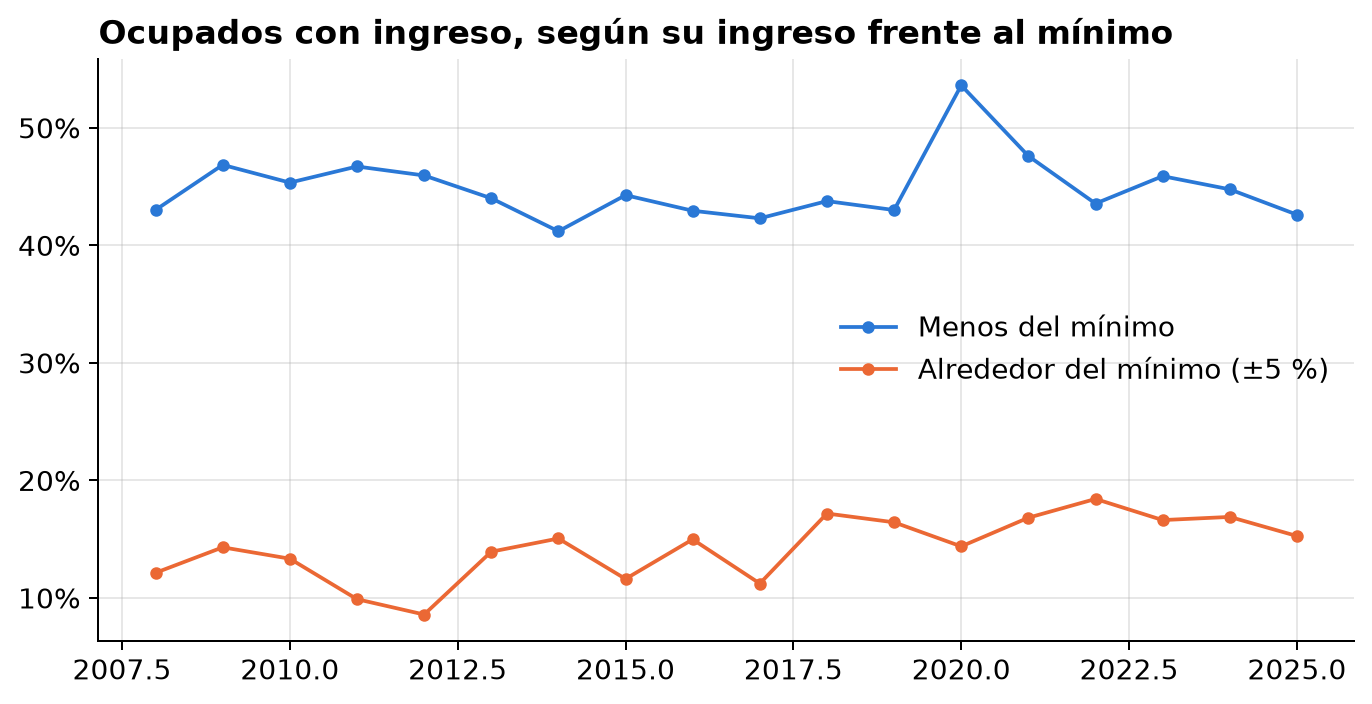

In [6]:
ax = cerca.plot(x="anio", y=["menos_del_minimo", "alrededor_del_minimo"], marker="o", ms=4,
                label=["Menos del mínimo", "Alrededor del mínimo (±5 %)"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("")
ax.set_title("Ocupados con ingreso, según su ingreso frente al mínimo");

Entre el 41 % y el 48 % de los ocupados con ingreso gana menos de 0,95 salarios mínimos todos los años,
salvo 2020 (54 %).